# Lab: transfer learning with PyTorch

*Practice in Deep Learning · 3 hours*

In the previous labs you trained LeNet-300 and LeNet-5 **from scratch** on MNIST: 60,000 labelled images, small, grayscale, with the digit centred in the frame.

In this lab you will classify photos of **pizza, steak and sushi** with about **75 training images per class**: color photos of different sizes, with the food anywhere in the picture. Instead of starting from random weights, you will start from a network already trained on the 1.3 million images of ImageNet, and adapt it to the new task: this is **transfer learning**.

**Objectives.** By the end of the lab you should be able to:
- explain why a CNN trained from scratch struggles when data is scarce;
- load a pretrained model from `torchvision.models` and identify its feature extractor and its classifier head;
- preprocess images the way the pretrained model expects;
- freeze layers and replace the head to solve a new task;
- analyse a classifier's errors, and choose between feature extraction and fine-tuning.

**How the lab works.**
- ✏️ **TODO** cells contain code for you to write. In parts 1 and 2, each one is followed by a check that prints ✅ when your code is correct.
- ✍️ **Your answer** cells: answer the questions in a few sentences.
- Run the cells in order, on a GPU. On Colab: *Runtime → Change runtime type → T4 GPU*.

| Part | Content | Time |
|---|---|---|
| 1 | Data, and a baseline trained from scratch | 35 min |
| 2 | Transfer learning: feature extraction | 35 min |
| 3 | Assignments A1 to A5 | 1 h 45 |
| Bonus | B1 and B2, if you finish early | |

<sub>Adapted from chapter 06 of D. Bourke, [*Learn PyTorch for Deep Learning*](https://www.learnpytorch.io/06_pytorch_transfer_learning/) (MIT License).</sub>

## Setup

The second cell defines helpers. You don't need to read it, just know what it provides:
- `plot_histories(histories)` plots the training curves of one or more models;
- `show_predictions(model, image_paths)` shows images with the predicted class and its probability (green: correct, red: wrong);
- the `check_*` functions test your TODOs.

In [1]:
import copy
import random
import zipfile
from locale import normalize
from pathlib import Path
from typing import cast

import matplotlib.pyplot as plt
import requests
import torch
import torchvision
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")

torch 2.15.0 | torchvision 0.29.2 | device: cpu


In [2]:
# @title Lab helpers (run this cell, no need to read it)
LAB_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def plot_histories(histories):
    """Loss and accuracy curves. `histories` maps a label to the dictionary returned by fit()."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
    for (label, h), color in zip(histories.items(), LAB_COLORS):
        epochs = range(1, len(h["train_loss"]) + 1)
        for split, style in [("train", "--"), ("test", "-")]:
            ax_loss.plot(epochs, h[f"{split}_loss"], style, color=color, lw=2, label=f"{label} ({split})")
            ax_acc.plot(epochs, h[f"{split}_acc"], style, color=color, lw=2)
    ax_acc.axhline(1 / len(class_names), color="gray", lw=1, ls=":")
    ax_acc.text(0.98, 1 / len(class_names) + 0.02, "chance", color="gray", ha="right",
                transform=ax_acc.get_yaxis_transform())
    ax_loss.set(title="Loss", xlabel="epoch")
    ax_acc.set(title="Accuracy", xlabel="epoch", ylim=(0, 1.02))
    for ax in (ax_loss, ax_acc):
        ax.grid(alpha=0.3)
    fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0.96), ncol=len(histories), frameon=False)
    plt.show()


@torch.no_grad()
def show_predictions(model, image_paths, ncols=4):
    """Images with the predicted class and its probability. Green: correct, red: wrong."""
    if len(image_paths) == 0:
        print("no image to show")
        return
    model.eval()
    ncols = min(ncols, len(image_paths))
    nrows = -(-len(image_paths) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.6 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, path in zip(axes.flat, image_paths):
        image = Image.open(path).convert("RGB")
        probs = model(transform(image).unsqueeze(0).to(device)).softmax(dim=1)[0]
        pred, true = class_names[probs.argmax()], Path(path).parent.name
        title, color = f"{pred} ({probs.max():.0%})", "black"
        if true in class_names:
            color = "green" if pred == true else "red"
            title += "" if pred == true else f"\ntrue: {true}"
        ax.imshow(image)
        ax.set_title(title, color=color)
    plt.show()


def check_transform(transform):
    steps = getattr(transform, "transforms", [])
    assert all(step is not Ellipsis for step in steps), "replace each ... with a transform"
    x = transform(Image.open(sorted(train_dir.glob("*/*.jpg"))[0]))
    assert isinstance(x, torch.Tensor), "the pipeline must return a tensor"
    assert tuple(x.shape) == (3, 224, 224), f"expected shape (3, 224, 224), got {tuple(x.shape)}"
    normalize = [step for step in steps if isinstance(step, transforms.Normalize)]
    assert normalize, "the pipeline must normalize the tensor"
    assert list(normalize[0].mean) == IMAGENET_MEAN and list(normalize[0].std) == IMAGENET_STD, \
        "normalize with IMAGENET_MEAN and IMAGENET_STD"
    print("✅ transform is correct")


def check_lenet(lenet_class):
    net = lenet_class(num_classes=3)
    out = net(torch.zeros(2, 3, 224, 224))
    assert tuple(out.shape) == (2, 3), f"expected an output of shape (2, 3), got {tuple(out.shape)}"
    n_params = sum(p.numel() for p in net.parameters())
    assert n_params == 61_411, f"expected 61,411 parameters, got {n_params:,}: check the layer sizes"
    print("✅ LeNet5 is correct")


def check_feature_extractor(make_fn):
    net = make_fn(num_classes=3)
    assert not torch.allclose(net.features[0][1].running_var, torch.ones(32)), \
        "load the pretrained weights: efficientnet_b0(weights=weights)"
    assert not any(p.requires_grad for p in net.features.parameters()), "every parameter of `features` must be frozen"
    head = net.classifier[-1]
    assert isinstance(head, nn.Linear) and head.out_features == 3, "the last layer must be a new nn.Linear with 3 outputs"
    assert all(p.requires_grad for p in net.classifier.parameters()), "the new head must be trainable"
    print("✅ make_feature_extractor is correct")


def check_head_optimizer(optimizer):
    assert isinstance(optimizer, torch.optim.Optimizer), "replace ... with an optimizer"
    n_params = sum(p.numel() for group in optimizer.param_groups for p in group["params"])
    assert n_params == 3_843, f"the optimizer must only receive the parameters of the head, it got {n_params:,}"
    print("✅ optimizer is correct")


def check_predict(predict_fn, model):
    y_true, y_pred, probs = (t.cpu() for t in predict_fn(model, test_loader))
    assert tuple(probs.shape) == (len(test_data), len(class_names)), "probs must have shape (n_images, n_classes)"
    assert torch.allclose(probs.sum(dim=1), torch.ones(len(probs)), atol=1e-4), "probs must be softmax probabilities"
    assert abs((y_pred == y_true).float().mean().item() - evaluate(model, test_loader)[1]) < 1e-6, \
        "the accuracy differs from evaluate(): check the labels"
    print("✅ predict is correct")

## Part 1: data, and a baseline trained from scratch (35 min)

### 1.1 The data

A small subset of [Food-101](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/), stored with one folder per class:

```
pizza_steak_sushi/
├── train/   pizza/  steak/  sushi/
└── test/    pizza/  steak/  sushi/
```

In [3]:
data_path = Path("data")
image_path = data_path / "pizza_steak_sushi"
train_dir, test_dir = image_path / "train", image_path / "test"

if not train_dir.is_dir():  # download only once
    url = "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/data/pizza_steak_sushi.zip"
    zip_file = data_path / "pizza_steak_sushi.zip"
    data_path.mkdir(exist_ok=True)
    zip_file.write_bytes(requests.get(url, timeout=60).content)
    with zipfile.ZipFile(zip_file) as archive:
        archive.extractall(image_path)
    zip_file.unlink()

for split_dir in (train_dir, test_dir):
    counts = {d.name: len(list(d.glob("*.jpg"))) for d in sorted(split_dir.iterdir())}
    print(f"{split_dir.name:5s} {counts}  total: {sum(counts.values())}")

train {'pizza': 78, 'steak': 75, 'sushi': 72}  total: 225
test  {'pizza': 25, 'steak': 19, 'sushi': 31}  total: 75


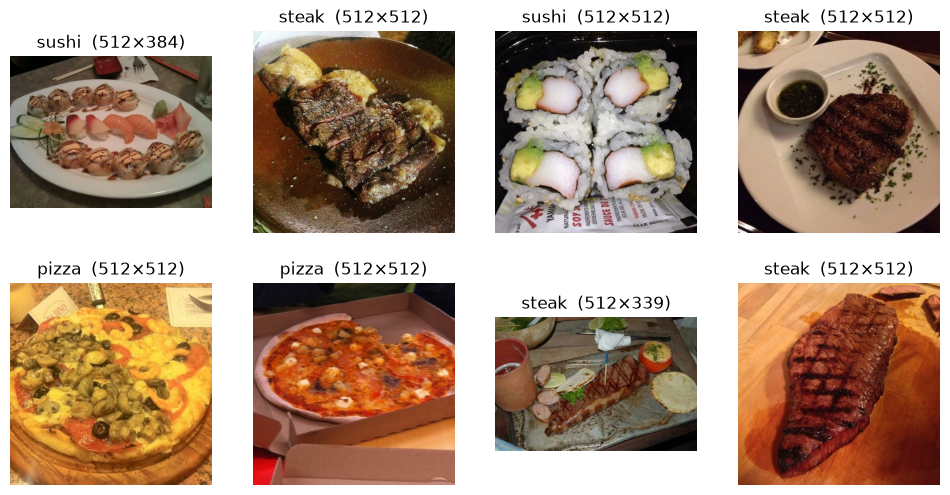

In [4]:
random.seed(0)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, path in zip(axes.flat, random.sample(sorted(train_dir.glob("*/*.jpg")), k=8)):
    image = Image.open(path)
    ax.imshow(image)
    ax.set_title(f"{path.parent.name}  ({image.width}×{image.height})")
    ax.axis("off")
plt.show()

> **Question 1.** List the differences with MNIST. Which ones make this task harder for a network trained from scratch?

✍️ **Your answer:** The differences consist of: MNIST is grayscale with 1 channel, while these are RGB with 3 channels, the image sizes jump from 28x28 of MNIST's to the 224x224 we have here, MNIST are centered, while here the food can be placed anywhere in the image, with noise such as clutter, different lighting, different angles, etc.

### 1.2 Preprocessing

A batch must contain tensors of identical size, so every image goes through the same pipeline:
1. resize to **224×224**, the resolution of the pretrained model of part 2;
2. convert to a tensor with values in [0, 1];
3. **normalize** each colour channel with the mean and standard deviation of **ImageNet**.

Step 3 is the same standardization as `Normalize((0.1307,), (0.3081,))` for MNIST, but with one mean and one std per colour channel. Why ImageNet's statistics rather than those of our dataset? The pretrained model was trained on inputs normalized this way, so our images must look the same to it.

✏️ **TODO 1.** Complete the pipeline with `transforms.Resize`, `transforms.ToTensor` and `transforms.Normalize`.

In [5]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# ✏️ TODO 1: complete the preprocessing pipeline
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # 1. resize to 224×224
    transforms.ToTensor(),  # 2. convert to a tensor with values in [0, 1]
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # 3. normalize with IMAGENET_MEAN and IMAGENET_STD
])

check_transform(transform)

✅ transform is correct


`datasets.ImageFolder` builds a dataset from the folder layout: each sub-folder is a class.

In [6]:
train_data = datasets.ImageFolder(train_dir, transform=transform)
test_data = datasets.ImageFolder(test_dir, transform=transform)
class_names = train_data.classes

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32)

images, labels = next(iter(train_loader))
print("classes:", class_names)
print("batch of images:", images.shape, "| batch of labels:", labels.shape)

classes: ['pizza', 'steak', 'sushi']
batch of images: torch.Size([32, 3, 224, 224]) | batch of labels: torch.Size([32])


### 1.3 Baseline: LeNet-5 from scratch

First, the approach of the previous labs: LeNet-5, with three changes. It takes 3 input channels (RGB), has 3 outputs, and ends its convolutional part with `nn.AdaptiveAvgPool2d((5, 5))`, which averages the feature maps down to 5×5 whatever the image size. The fully connected layers therefore keep their 16·5·5 = 400 inputs, even with 224×224 images.

The model is written as two blocks: `features` (convolutions) and `classifier` (fully connected layers). Keep this split in mind: transfer learning is built on it.

✏️ **TODO 2.** Complete the two blocks.

In [7]:
class LeNet5(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        # ✏️ TODO 2: complete the two blocks
        self.features = nn.Sequential(        # image -> feature maps
            nn.Conv2d(3, 6, kernel_size=5),   # conv 5×5 (3 -> 6 channels), ReLU, max-pool 2×2
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5), # conv 5×5 (6 -> 16 channels), ReLU, max-pool 2×2
            nn.ReLU(),
            nn.MaxPool2d(2),
            # adaptive average pooling to 5×5
            nn.AdaptiveAvgPool2d((5, 5)),
        )
        self.classifier = nn.Sequential(      # feature maps -> class scores
            nn.Flatten(),                     # flatten, then linear layers 400 -> 120 -> 84 -> num_classes, with ReLU in between
            nn.Linear(400, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return f"{trainable:,} trainable parameters (out of {total:,})"


check_lenet(LeNet5)
print(count_params(LeNet5(num_classes=3)))

✅ LeNet5 is correct
61,411 trainable parameters (out of 61,411)


### 1.4 Training loop

The loop from the MNIST labs, wrapped in functions so that it can be reused for every model. Nothing in it is specific to transfer learning.

> **Note.** We evaluate on the test set after each epoch to follow training. In a real project, you would make your choices on a separate validation set and use the test set only once, at the end.

In [8]:
loss_fn = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def fit(model, optimizer, epochs):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        test_loss, test_acc = evaluate(model, test_loader)
        for key, value in zip(history, (train_loss, train_acc, test_loss, test_acc)):
            history[key].append(value)
        print(f"epoch {epoch:2d} | train: loss {train_loss:.3f}, acc {train_acc:.0%}"
              f" | test: loss {test_loss:.3f}, acc {test_acc:.0%}")
    return history

> **Question 2.** With 3 classes, chance level is about 33%. What test accuracy do you expect from LeNet-5 after 10 epochs? (Just make a guess before running the next cell.)

**Answer Question 2:** I would say about 40% after the 10 epochs.

In [9]:
torch.manual_seed(42)
lenet = LeNet5(num_classes=len(class_names)).to(device)
optimizer = torch.optim.Adam(lenet.parameters(), lr=1e-3)
history_lenet = fit(lenet, optimizer, epochs=40)

epoch  1 | train: loss 1.084, acc 41% | test: loss 1.094, acc 31%
epoch  2 | train: loss 1.000, acc 51% | test: loss 1.028, acc 43%
epoch  3 | train: loss 0.907, acc 56% | test: loss 1.031, acc 47%
epoch  4 | train: loss 0.870, acc 59% | test: loss 1.004, acc 48%
epoch  5 | train: loss 0.886, acc 61% | test: loss 1.003, acc 43%
epoch  6 | train: loss 0.937, acc 55% | test: loss 1.063, acc 39%
epoch  7 | train: loss 0.852, acc 60% | test: loss 1.016, acc 47%
epoch  8 | train: loss 0.827, acc 59% | test: loss 1.007, acc 49%
epoch  9 | train: loss 0.802, acc 63% | test: loss 1.007, acc 48%
epoch 10 | train: loss 0.816, acc 64% | test: loss 0.985, acc 51%
epoch 11 | train: loss 0.854, acc 59% | test: loss 0.939, acc 57%
epoch 12 | train: loss 0.762, acc 67% | test: loss 0.950, acc 53%
epoch 13 | train: loss 0.740, acc 67% | test: loss 0.929, acc 53%
epoch 14 | train: loss 0.767, acc 57% | test: loss 0.915, acc 55%
epoch 15 | train: loss 0.705, acc 68% | test: loss 0.997, acc 52%
epoch 16 |

LeNet-5 does better than chance, but not by much. From random weights, 225 images are not enough to learn convolutional filters that capture what distinguishes a pizza from a steak or a sushi.

> **Question 3.** Would more epochs help? Re-run the cell above with `epochs=40` and compare the training and test accuracy.

✍️ **Your answer:** With 10 epochs the run ended at around 51% accuracy, with the 40 epochs the iterations had a lot more overshooting and then overcorrecting, in the end it got a better result of 63% but one more epoch, and it could have overshot again and the result would have been the same as the lower epochs.

## Part 2: transfer learning with feature extraction (35 min)

### 2.1 A pretrained model

The convolutional layers of a CNN learn a hierarchy of features: edges and colours in the first layers, then textures and simple shapes, then object parts. When the network is trained on a large and varied dataset, these features are useful far beyond the classes it was trained on ([Yosinski et al., 2014](https://arxiv.org/abs/1411.1792)). Transfer learning reuses them.

[`torchvision.models`](https://pytorch.org/vision/stable/models.html) provides many architectures with weights pretrained on ImageNet (1000 classes). We use **EfficientNet-B0**: 5.3 M parameters, 77.7% top-1 accuracy on ImageNet. The weights (20 MB) are downloaded the first time.

In [10]:
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT   # the best available ImageNet weights
model = torchvision.models.efficientnet_b0(weights=weights).to(device)

> Older tutorials write `efficientnet_b0(pretrained=True)`. This argument is deprecated: use `weights=` as above.

`print(model)` lists more than 300 modules. The top level is enough to understand the model:

In [11]:
for name, module in model.named_children():
    n_params = sum(p.numel() for p in module.parameters())
    print(f"{name:10s} {type(module).__name__:18s} {n_params:>10,} parameters")
print("\nmodel.classifier =", model.classifier)

features   Sequential          4,007,548 parameters
avgpool    AdaptiveAvgPool2d           0 parameters
classifier Sequential          1,281,000 parameters

model.classifier = Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


EfficientNet-B0 has the same structure as our LeNet-5:

| | LeNet-5 (part 1) | EfficientNet-B0 |
|---|---|---|
| `features` | 2 convolutional layers, trained on our 225 images | 16 convolutional blocks, trained on 1.3 M ImageNet images |
| pooling | `AdaptiveAvgPool2d((5, 5))` | `AdaptiveAvgPool2d(1)`: each image becomes a vector of **1280 features** |
| `classifier` | 3 linear layers → 3 classes | dropout + 1 linear layer → **1000** ImageNet classes |

### 2.2 The preprocessing must match

The weights come with the preprocessing used to train them:

In [12]:
weights.transforms()

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

Same size (224×224) and same normalization as our `transform`. The official recipe resizes to 256 and then crops the central 224×224, a minor difference. We wrote ours by hand to see each step; in practice, simply use `transform = weights.transforms()`.

### 2.3 What does the model predict before we change anything?

The pretrained model already works... for ImageNet's 1000 classes. Let's show it one test image of each of our classes:

In [13]:
categories = weights.meta["categories"]   # names of the 1000 ImageNet classes
model.eval()
with torch.no_grad():
    for name in class_names:
        path = sorted((test_dir / name).glob("*.jpg"))[0]
        x = transform(Image.open(path).convert("RGB")).unsqueeze(0).to(device)  # a batch of one image
        probs = model(x).softmax(dim=1)[0]
        top3 = probs.topk(3)
        guesses = ", ".join(f"{categories[i]} ({p:.0%})" for p, i in zip(top3.values, top3.indices))
        print(f"{name:5s} → {guesses}")

pizza → pizza (68%), potpie (8%), plate (2%)
steak → mashed potato (45%), meat loaf (12%), plate (11%)
sushi → plate (72%), tray (5%), ice cream (5%)


Pizza is one of the 1000 ImageNet classes, and the model recognizes it. Steak and sushi are not, so the model answers with ImageNet classes that look similar, or with what surrounds the food. The `features` clearly capture relevant information about these images; it is the `classifier`, tied to ImageNet's 1000 classes, that does not fit our problem.

### 2.4 Feature extraction: freeze the features, replace the head

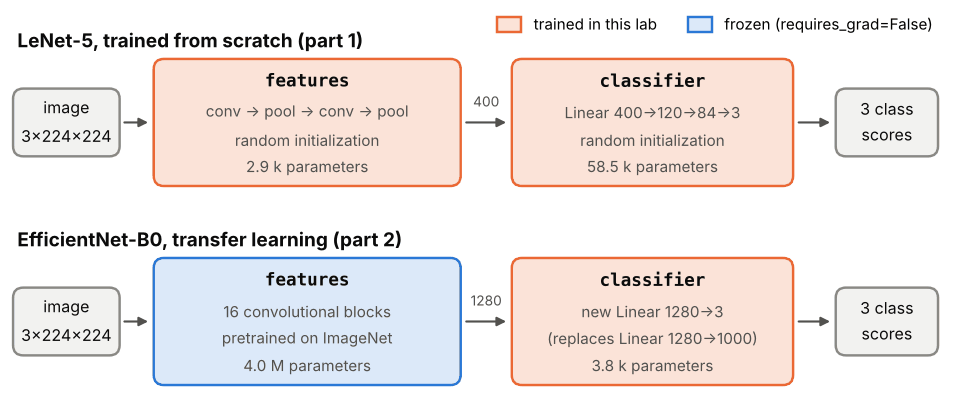

Two steps:
1. **Freeze** `features`: set `requires_grad = False` on all its parameters. Autograd then computes no gradient for them, and the optimizer leaves them unchanged. (So far, every parameter had the default `requires_grad=True`.)
2. **Replace** the last layer of `classifier` (`model.classifier[1]`) with a new `nn.Linear` with 1280 inputs and 3 outputs. A new layer is randomly initialized and trainable.

✏️ **TODO 3.** Write `make_feature_extractor`, which returns a pretrained EfficientNet-B0 ready for feature extraction.

In [14]:
def make_feature_extractor(num_classes):
    model = torchvision.models.efficientnet_b0(weights=weights)
    # ✏️ TODO 3
    model = torchvision.models.efficientnet_b0(weights=weights)
    # 1. freeze every parameter of model.features
    for param in model.features.parameters():
        param.requires_grad = False
    # 2. replace model.classifier[1] with a new nn.Linear (reuse the in_features of the old layer)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


check_feature_extractor(make_feature_extractor)

✅ make_feature_extractor is correct


In [15]:
torch.manual_seed(42)
model = make_feature_extractor(len(class_names)).to(device)
print(count_params(model))

3,843 trainable parameters (out of 4,011,391)


> **Question 4.** Where does this number of trainable parameters come from? Compare it with LeNet-5 and with LeNet-300 (about 266,000 parameters).

✍️ **Your answer:** The only trainable layer is the new head, nn.Linear(1280, 3) which is the 3843 out of 4m parameters. Lenet-5 had 60k and lenet-300 had 250k, while those had to be trained from scratch, this transfer model only learning a linear classifier.

### 2.5 Training

The same loop, optimizer, learning rate and number of epochs as the baseline: only the model has changed.

✏️ **TODO 4.** Create an Adam optimizer (learning rate 1e-3) that receives **only the parameters of the head**.

In [16]:
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)  # ✏️ TODO 4
check_head_optimizer(optimizer)

history_tl = fit(model, optimizer, epochs=10)

✅ optimizer is correct
epoch  1 | train: loss 1.050, acc 44% | test: loss 0.877, acc 65%
epoch  2 | train: loss 0.856, acc 65% | test: loss 0.748, acc 73%
epoch  3 | train: loss 0.715, acc 84% | test: loss 0.669, acc 87%
epoch  4 | train: loss 0.628, acc 86% | test: loss 0.639, acc 88%
epoch  5 | train: loss 0.584, acc 87% | test: loss 0.575, acc 89%
epoch  6 | train: loss 0.553, acc 88% | test: loss 0.524, acc 89%
epoch  7 | train: loss 0.505, acc 87% | test: loss 0.493, acc 87%
epoch  8 | train: loss 0.466, acc 86% | test: loss 0.466, acc 89%
epoch  9 | train: loss 0.415, acc 93% | test: loss 0.462, acc 91%
epoch 10 | train: loss 0.416, acc 92% | test: loss 0.446, acc 91%


### 2.6 Results

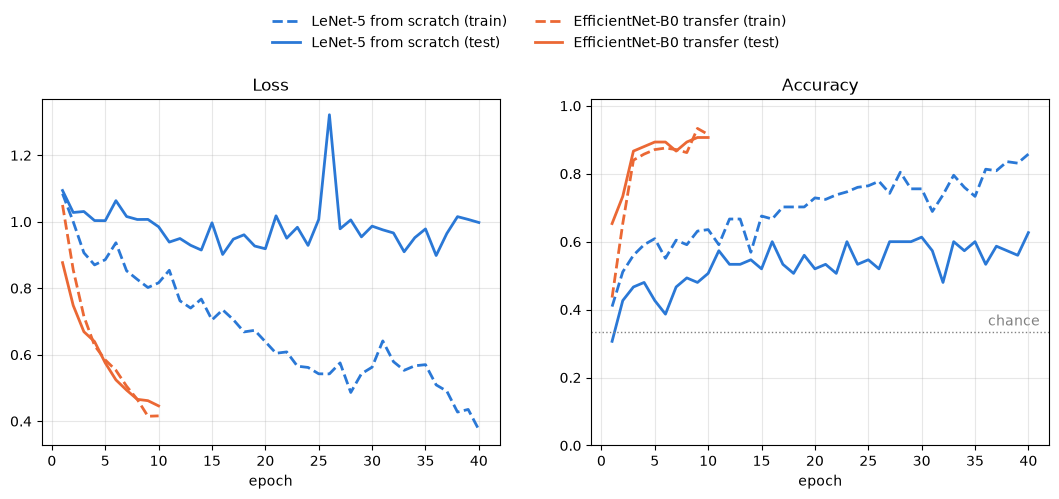

In [17]:
plot_histories({"LeNet-5 from scratch": history_lenet, "EfficientNet-B0 transfer": history_tl})

Same data, same training loop, same number of epochs: the only difference is where the convolutional features come from.

> **Question 5.**
> 1. Compare the gap between the training and test curves of the two models. What does it tell you?
> 2. Why does the transfer model reach a good accuracy within two or three epochs, when LeNet-5 never does?
> 3. In the first epochs, the training accuracy of the transfer model is *lower* than its test accuracy. How is that possible? *Hint: when is the training accuracy measured, and what does `model.train()` change in the classifier?*

✍️ **Your answer:**
1. LN5, with 60k trainable parameters and a small batch of images overfits, while the transfer model's training and test curves stay low, generalising well, having a small amount of params and no space to memorize.
2. The hard part which was learning the visual textures was already done on ImageNet. LN5 has to learn its filters from scratch with only 225 images, while this transfer only fits one linear layer on top.
3. Training accuracy is averaged over batches during the epoch while the weights are still changes, and also because of the dropout, model.train() turns on the dropout layer in the classifier.

Some predictions on test images (green: correct, red: wrong):

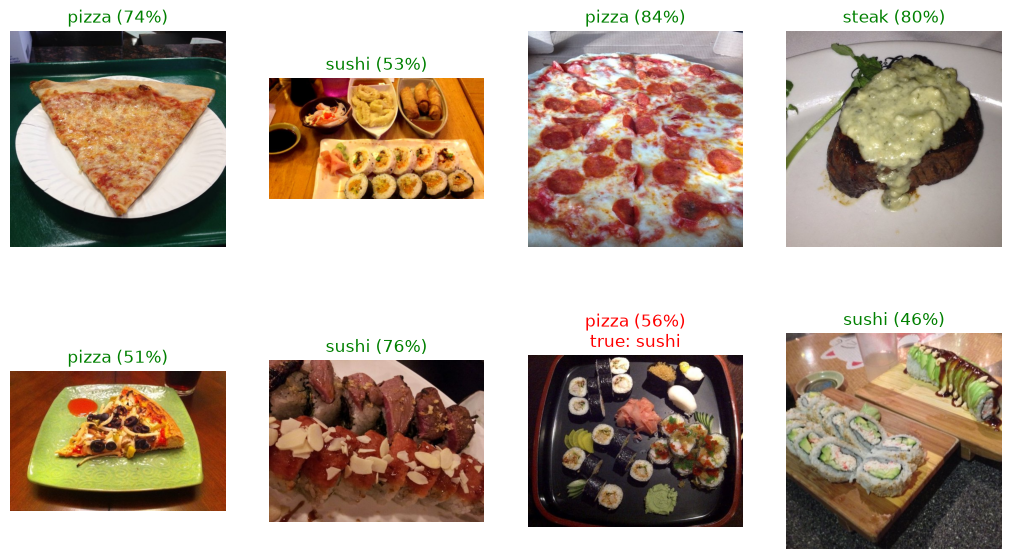

In [18]:
random.seed(1)
show_predictions(model, random.sample(sorted(test_dir.glob("*/*.jpg")), k=8))

## Part 3: assignments (1 h 45)

Write your code in the ✏️ cells: the skeletons and hints are there to help, and you can change them. The assignments are independent, except A2, which uses `predict` and its results from A1.

### A1. Error analysis (25 min)

An accuracy is a single number. To understand what the model gets wrong, look at the confusion matrix and at the mistakes themselves.

1. Complete `predict`, which returns the true labels, the predicted labels and the softmax probabilities on a whole dataset.
2. Plot the confusion matrix with [`ConfusionMatrixDisplay.from_predictions`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_predictions).
3. Show the misclassified test images, from the most confident mistake to the least confident. *Hint:* `test_data.samples[i]` is the `(path, label)` pair of the i-th test image, in the same order as `test_loader`.

In [19]:
@torch.no_grad()
def predict(model, loader):
    # returns the true labels, predicted labels and softmax probabilities on the whole dataset, as CPU tensors
    model.eval()
    all_labels, all_probs = [], []
    for x, y in loader: # ✏️ TODO A1.1: compute the softmax probabilities of the batch, store them and the labels
        probs = model(x.to(device)).softmax(dim=1)
        all_probs.append(probs.cpu())
        all_labels.append(y)
    labels, probs = torch.cat(all_labels), torch.cat(all_probs)
    return labels, probs.argmax(dim=1), probs


check_predict(predict, model)
y_true, y_pred, probs = predict(model, test_loader)

✅ predict is correct


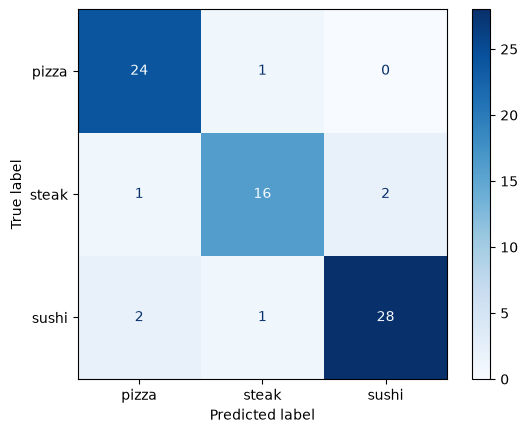

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

# ✏️ TODO A1.2: plot the confusion matrix (rows: true class, columns: predicted class)
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, cmap="Blues")
plt.show()

7 mistakes out of 75 test images


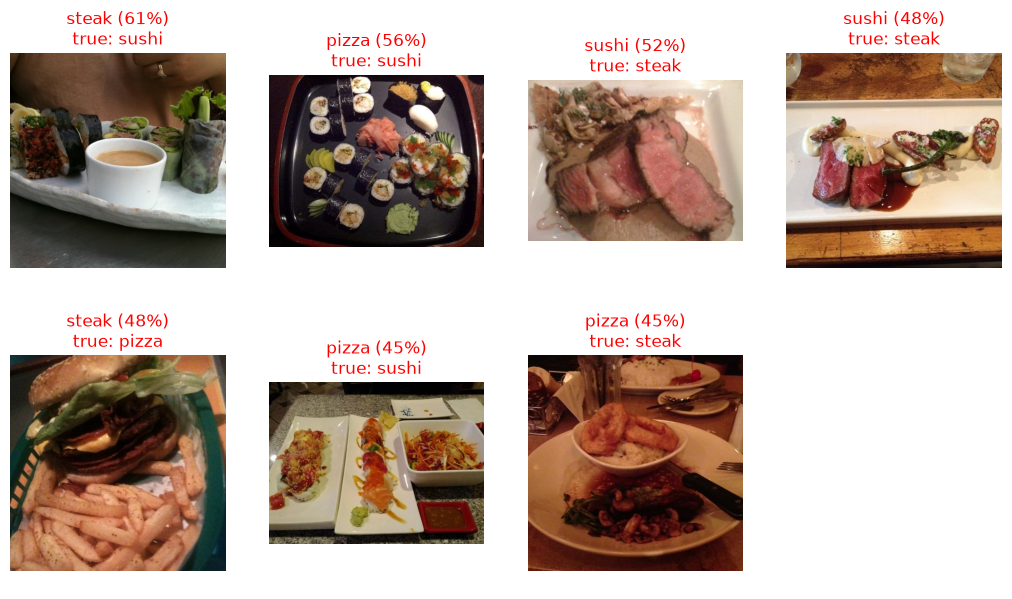

In [21]:
# ✏️ TODO A1.3: indices of the wrong predictions, sorted by decreasing probability of the predicted class
wrong = (y_pred != y_true).nonzero().flatten()
confidence = probs[wrong, y_pred[wrong]]
mistakes = wrong[confidence.argsort(descending=True)].tolist()

print(f"{len(mistakes)} mistakes out of {len(y_true)} test images")
show_predictions(model, [test_data.samples[i][0] for i in mistakes])

> **Questions.** Which classes are confused the most? Look at the misclassified images: are the mistakes understandable? Is a high probability a guarantee of a correct answer?

✍️ **Your answer:**
It most confuses plates for sushi, it being one of the most variously colored meals from our classes it most certainly looks different between each plate, and their colors matter aswell, steak and sushi both having darker colors. The misclassified images tend to be closeups, unusual angles, bad lighting, several foods, so pretty much noise is what breaks in here.

### A2. Outside the three classes (20 min)

The model always answers *pizza*, *steak* or *sushi*, even for an image that is none of them. What does it say about an MNIST digit, and how confident is it?

1. Build `mnist_transform`, which turns an MNIST digit into an input our model accepts. *Hints:* the digits have 1 channel and `transforms.Grayscale(num_output_channels=3)` copies it into 3; `transform` can be used as a step of another `Compose`.
2. With `predict`, compare the **confidence** (the probability of the predicted class) on the food test images and on 300 MNIST digits: plot both histograms (`plt.hist`), and count the classes predicted for the digits.

In [22]:
mnist_transform = transforms.Compose([transforms.Grayscale(num_output_channels=3), transform])  # ✏️ TODO A2.1

mnist = datasets.MNIST("data", train=False, download=True, transform=mnist_transform)
mnist_loader = DataLoader(torch.utils.data.Subset(mnist, range(300)), batch_size=32)
print(mnist[0][0].shape)

torch.Size([3, 224, 224])


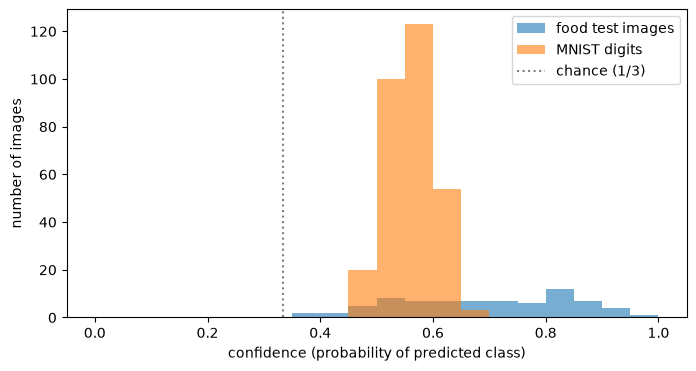

digits predicted as pizza: 0
digits predicted as steak: 0
digits predicted as sushi: 300
mean confidence: food 69% | digits 56%


In [23]:
# ✏️ TODO A2.2: histograms of the confidence on the food test images and on the digits,
# and number of digits predicted as each class
_, food_pred, food_probs = predict(model, test_loader)
_, mnist_pred, mnist_probs = predict(model, mnist_loader)

food_conf = food_probs.max(dim=1).values     # probability of the predicted class
mnist_conf = mnist_probs.max(dim=1).values

plt.figure(figsize=(8, 4))
plt.hist(food_conf, bins=20, range=(0, 1), alpha=0.6, label="food test images")
plt.hist(mnist_conf, bins=20, range=(0, 1), alpha=0.6, label="MNIST digits")
plt.axvline(1 / len(class_names), color="gray", ls=":", label="chance (1/3)")
plt.xlabel("confidence (probability of predicted class)")
plt.ylabel("number of images")
plt.legend()
plt.show()

counts = torch.bincount(mnist_pred, minlength=len(class_names))
for name, c in zip(class_names, counts):
    print(f"digits predicted as {name:5s}: {c.item()}")
print(f"mean confidence: food {food_conf.mean():.0%} | digits {mnist_conf.mean():.0%}")

> **Questions.** Does the model tell you that a digit is not food? Could a threshold on the confidence detect such inputs? What would you change to handle images that belong to none of the classes?
>
> *Optional:* upload a photo of your own (Colab: *Files* panel on the left) and run `show_predictions(model, ["your_photo.jpg"])`.

✍️ **Your answer:**
All 300 digits got predicted as sushi, probably because of the white/black colours and simple shapes looking ckoser to rice and seaweed than to pizza or steak. The mean confidence on digits was 56%, compared to 69% on food, so it's lower but still well above chance 33%, the model is fairly sure about imafes that aren't even food.

### A3. Pretrained weights or architecture? (15 min)

Is the result of part 2 due to the EfficientNet architecture, or to its ImageNet weights? Train the **same architecture from random weights** (`weights=None`, `num_classes=3`), all layers trainable, with the same optimizer and number of epochs, and compare.

In [ ]:
torch.manual_seed(42)
scratch = torchvision.models.efficientnet_b0(weights=None, num_classes=len(class_names)).to(device)  # ✏️ TODO A3
optimizer = torch.optim.Adam(scratch.parameters(), lr=1e-3)  # ✏️ Adam on all its parameters
history_scratch = fit(scratch, optimizer, epochs=10)  # ✏️ 10 epochs

plot_histories({"LeNet-5 from scratch": history_lenet,
                "EfficientNet-B0 transfer": history_tl,
                "EfficientNet-B0 from scratch": history_scratch})

> **Questions.** Which one explains the result of part 2: the architecture or the pretrained weights? How many parameters does each EfficientNet train?

✍️ **Your answer:**
It's the pretrained weights, EfficientNet from scratch stayed at chance while the transfer one got 91% with the same architecture. Scratch trains all about 4M params, transfer only 3,843.

### A4. Fine-tuning (20 min)

So far we trained only a new head on top of frozen features: this is **feature extraction**. **Fine-tuning** goes one step further: it also unfreezes the last blocks of `features`, and trains them with a small learning rate so that the pretrained weights are adjusted rather than overwritten.

| Strategy | Starting weights | What is trained | When to use it |
|---|---|---|---|
| From scratch (MNIST labs) | random | all layers | large dataset |
| Feature extraction (part 2) | pretrained | new head only | small dataset, images similar to the pretraining data |
| Fine-tuning | pretrained | new head + last blocks, small learning rate | more data, or images unlike the pretraining data (medical, satellite...) |

Starting from a copy of the model of part 2, unfreeze its **last two blocks** (`ft_model.features[-2:]`) and train for 5 more epochs. The pretrained layers must get a 10 times smaller learning rate than the head: give Adam two *parameter groups*, `[{"params": ..., "lr": 1e-4}, {"params": ..., "lr": 1e-3}]`.

In [25]:
ft_model = copy.deepcopy(model)  # copy: the model from part 2 stays unchanged

# ✏️ TODO A4: unfreeze ft_model.features[-2:]
for param in ft_model.features[-2:].parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam([  # ✏️ ... and Adam with two groups
    {"params": ft_model.features[-2:].parameters(), "lr": 1e-4},  # pretrained blocks: 10× smaller
    {"params": ft_model.classifier.parameters(), "lr": 1e-3},     # head
])

print(count_params(ft_model))
history_ft = fit(ft_model, optimizer, epochs=5)
print(f"test accuracy: {history_tl['test_acc'][-1]:.0%} before fine-tuning, {history_ft['test_acc'][-1]:.0%} after")

1,133,235 trainable parameters (out of 4,011,391)
epoch  1 | train: loss 0.367, acc 94% | test: loss 0.366, acc 91%
epoch  2 | train: loss 0.295, acc 94% | test: loss 0.323, acc 91%
epoch  3 | train: loss 0.224, acc 96% | test: loss 0.286, acc 95%
epoch  4 | train: loss 0.199, acc 98% | test: loss 0.260, acc 93%
epoch  5 | train: loss 0.167, acc 97% | test: loss 0.251, acc 95%
test accuracy: 91% before fine-tuning, 95% after


> **Questions.**
> 1. Does the test accuracy improve? With 75 test images, how many points of accuracy is one image worth? Is the difference meaningful?
> 2. What happens to the training accuracy? What is the risk of fine-tuning with only 225 images?
> 3. Why a smaller learning rate for the pretrained layers?

✍️ **Your answer:**
1. It went from 91% to 95%, so only 3 more images right out of 75, small and could be noise.
2. Training accuracy got to 97–98%, with 1.1M params and 225 images it risks overfitting.
3. The pretrained weights are already good, a big lr would overwrite them.

### A5. Another backbone: ResNet-18 (25 min)

The recipe works with any pretrained network, but each architecture organizes and names its layers differently. Apply it to **ResNet-18** (11.7 M parameters, 69.8% top-1 on ImageNet).

1. Load ResNet-18 with its ImageNet weights. Print its top-level modules (as in 2.1) and its preprocessing (`resnet_weights.transforms()`). What is the head called? Can we keep our `transform`?
2. Freeze **all** its parameters, then replace the head with a new linear layer with 3 outputs.
3. Train the head for 10 epochs (Adam, learning rate 1e-3) and compare with EfficientNet-B0.

In [26]:
resnet_weights = torchvision.models.ResNet18_Weights.DEFAULT
resnet = torchvision.models.resnet18(weights=resnet_weights)

# ✏️ TODO A5.1: print the top-level modules of resnet and resnet_weights.transforms()
for name, module in resnet.named_children():
    n_params = sum(p.numel() for p in module.parameters())
    print(f"{name:10s} {type(module).__name__:18s} {n_params:>10,} parameters")

print("\nresnet.fc =", resnet.fc)
print(resnet_weights.transforms())

0.6%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/iediot/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


conv1      Conv2d                  9,408 parameters
bn1        BatchNorm2d               128 parameters
relu       ReLU                        0 parameters
maxpool    MaxPool2d                   0 parameters
layer1     Sequential            147,968 parameters
layer2     Sequential            525,568 parameters
layer3     Sequential          2,099,712 parameters
layer4     Sequential          8,393,728 parameters
avgpool    AdaptiveAvgPool2d           0 parameters
fc         Linear                513,000 parameters

resnet.fc = Linear(in_features=512, out_features=1000, bias=True)
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [27]:
torch.manual_seed(42)
# ✏️ TODO A5.2: freeze all the parameters of resnet, then replace its head
for param in resnet.parameters():
    param.requires_grad = False
resnet.fc = nn.Linear(resnet.fc.in_features, len(class_names))  # 512 -> 3, trainable

resnet = resnet.to(device)
print(count_params(resnet))

1,539 trainable parameters (out of 11,178,051)


epoch  1 | train: loss 1.048, acc 50% | test: loss 1.042, acc 40%
epoch  2 | train: loss 0.919, acc 56% | test: loss 0.735, acc 73%
epoch  3 | train: loss 0.891, acc 53% | test: loss 0.726, acc 75%
epoch  4 | train: loss 0.702, acc 78% | test: loss 0.841, acc 56%
epoch  5 | train: loss 0.751, acc 61% | test: loss 0.607, acc 81%
epoch  6 | train: loss 0.585, acc 81% | test: loss 0.619, acc 77%
epoch  7 | train: loss 0.598, acc 76% | test: loss 0.528, acc 81%
epoch  8 | train: loss 0.566, acc 78% | test: loss 0.637, acc 68%
epoch  9 | train: loss 0.475, acc 87% | test: loss 0.519, acc 84%
epoch 10 | train: loss 0.439, acc 89% | test: loss 0.454, acc 91%


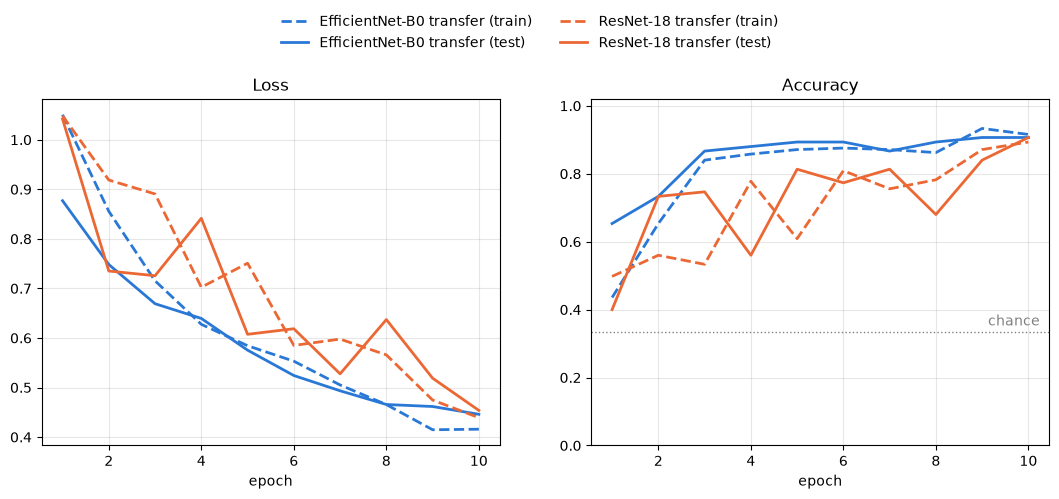

In [28]:
# ✏️ TODO A5.3: train the head for 10 epochs, then compare with EfficientNet-B0 using plot_histories
optimizer = torch.optim.Adam(resnet.fc.parameters(), lr=1e-3)
history_resnet = fit(resnet, optimizer, epochs=10)
plot_histories({"EfficientNet-B0 transfer": history_tl, "ResNet-18 transfer": history_resnet})

> **Questions.** What is the head of ResNet-18 called, and how many features does it receive? Why must you freeze *before* replacing the head? How does ResNet-18 compare with EfficientNet-B0?

✍️ **Your answer:**
The head is fc and gets 512 features. You freeze first because the new layer is trainable by default, freezing after would freeze it too. ResNet also got 91% like EfficientNet, but its curves were way noisier.

## Bonus (if you finish early)

### B1. Are the features really frozen?

`requires_grad = False` stops the gradient updates. But the BatchNorm layers inside `features` also store running statistics (`running_mean`, `running_var`), and those are updated at every forward pass in `train()` mode.

1. Compare the first BatchNorm layer (`features[0][1]`) and the first convolution (`features[0][0]`) of `model`, trained in part 2, with those of a freshly loaded EfficientNet-B0. What changed during training?
2. Complete `FrozenFeatureExtractor`, which keeps its features in eval mode even when the model is put in train mode, by overriding `nn.Module.train`. Train it and compare with part 2.

In [ ]:
fresh = torchvision.models.efficientnet_b0(weights=weights)
# ✏️ TODO B1.1: largest absolute change of features[0][1].running_mean, and of features[0][0].weight

In [ ]:
class FrozenFeatureExtractor(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.net = make_feature_extractor(num_classes)

    def forward(self, x):
        return self.net(x)

    def train(self, mode=True):
        super().train(mode)  # puts every submodule in train mode (or eval mode if mode=False)
        # ✏️ TODO B1.2: put self.net.features back in eval mode
        return self


torch.manual_seed(42)
frozen = FrozenFeatureExtractor(len(class_names)).to(device)
optimizer = torch.optim.Adam(frozen.net.classifier.parameters(), lr=1e-3)
history_frozen = fit(frozen, optimizer, epochs=10)

change = (frozen.net.features[0][1].running_mean.cpu() - fresh.features[0][1].running_mean).abs().max()
print(f"largest change of running_mean: {change:.3f}")
plot_histories({"BatchNorm statistics updated (part 2)": history_tl, "BatchNorm statistics frozen": history_frozen})

> **Questions.** What changed in `features` during the training of part 2? Does freezing the BatchNorm statistics change the accuracy?
>
> *Optional:* the ResNet-18 curves of A5 may have been noisy. Does keeping its backbone in eval mode help?

✍️ **Your answer:**

### B2. More data

Is transfer learning still useful with more data? The same classes with **twice as many images** are available at `https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/data/pizza_steak_sushi_20_percent.zip`. Download it (as in 1.1), rebuild `train_loader` and `test_loader` on it, and retrain LeNet-5 and the feature extractor for 10 epochs each.

⚠️ This replaces the data loaders used by `fit`: do it last.

In [ ]:
# ✏️ TODO B2

> **Questions.** Which model benefits more from twice as much data? What does it suggest about when transfer learning matters most?

✍️ **Your answer:** 

## Takeaways

- Trained from scratch on a few hundred images, a CNN overfits: it memorizes the training images instead of learning features that generalize.
- A network pretrained on a large dataset already has such features: keep its `features`, replace its `classifier`, and train only the new head. Few trainable parameters, fast training, good accuracy.
- Prepare the inputs exactly as during pretraining (size, normalization): `weights.transforms()` gives the recipe.
- Freezing a layer means setting `requires_grad = False` on its parameters; give the optimizer only the parameters that should be trained.
- Accuracy is not enough: look at the confusion matrix and at the mistakes, and remember that a softmax classifier always picks one of its classes.
- Before designing a model from scratch, look for a pretrained one: [`torchvision.models`](https://pytorch.org/vision/stable/models.html), [timm](https://huggingface.co/docs/timm), the [Hugging Face Hub](https://huggingface.co/models).